# TVP-VAR based Diebold-Yilmaz Spillover Index

Notebook ini berisi implementasi **Time-Varying Parameter Vector Autoregression (TVP-VAR)** untuk menghitung **Spillover Index** dinamis (Diebold-Yilmaz).

### Referensi Utama (Sitasi untuk Bab 3)
- **Antonakakis, N., Chatziantoniou, I., & Gabauer, D. (2020).** *Refined measures of dynamic connectedness based on time-varying parameter vector autoregressions.* Journal of Risk and Financial Management, 13(4), 84.
  > **Catatan Metodologi:** Antonakakis et al. (2020) mengusulkan penggunaan TVP-VAR dengan *forgetting factors* (diadopsi dari Koop & Korobilis, 2014) untuk mengatasi batasan ukuran *rolling-window* yang acak pada metode Diebold-Yilmaz (2012) klasik, sekaligus menghindari *curse of dimensionality* pada VAR berukuran besar.
- **Koop, G., & Korobilis, D. (2014).** *A new macroeconomics measure of inflation.* Economics Letters, 116(3), 269-272. (Untuk algoritma forgetting factor Kalman Filter).
- **Diebold, F. X., & Yilmaz, K. (2012).** *Better to give than to receive: Predictive directional measurement of volatility spillovers.* International Journal of Forecasting, 28(1), 57-66. (Untuk kerangka dasar Spillover Index / Generalized FEVD).

In [37]:
import os
import sys
import shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.linalg import pinv

# Auto-detect BASE_DIR: Kaggle vs local execution
if os.path.exists("/kaggle/input"):
    BASE_DIR = "/kaggle/input"
    DATA_DIR = os.path.join(BASE_DIR, "data")
    RESULTS_DIR = "/kaggle/working/results"
elif os.path.exists("../data"):
    BASE_DIR = os.path.abspath("..")
    DATA_DIR = os.path.join(BASE_DIR, "data")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")
else:
    BASE_DIR = os.path.abspath(".")
    DATA_DIR = os.path.join(BASE_DIR, "data")
    RESULTS_DIR = os.path.join(BASE_DIR, "results")

CLEAN_DATA_DIR = os.path.join(DATA_DIR, "clean")
os.makedirs(RESULTS_DIR, exist_ok=True)

# Setting tampilan plot
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['figure.dpi'] = 150


## 1. Load Data
Kita memuat `dataset_garch_baseline.csv` yang sudah disiapkan melalui listwise deletion (1.556 baris). Kita memfilter 8 instrumen inti untuk analisis spillover, dan menyimpan 3 variabel lainnya (^JKSE, ^VIX, IDR=X) untuk uji robustness terpisah.

In [38]:
data_path = os.path.join(CLEAN_DATA_DIR, 'dataset_garch_baseline.csv')
df = pd.read_csv(data_path)

# Variabel inti untuk Spillover Index (8 variabel)
core_vars = [
    'ret_saham_nvda', 'ret_saham_msft', 'ret_saham_tsla', 'ret_saham_googl', 'ret_saham_meta', 
    'ret_crypto_btc_usd', 'ret_crypto_eth_usd', 'ret_crypto_btc_idr_indodax'
]

# Robustness vars (tidak dimasukkan di TVP-VAR inti untuk menghindari dimensionality issues)
robustness_vars = ['ret_konteks_ihsg', 'ret_konteks_vix', 'ret_konteks_usdidr']

dates = pd.to_datetime(df['Date'])
Y = (df[core_vars] ** 2).values

print("Jumlah nilai 0 per kolom:", (Y == 0).sum(axis=0))
print("Std per kolom:", np.std(Y, axis=0))

# Cek distribusi squared return (diharapkan right-skewed) sebelum standardisasi
print("Distribusi Variabel Squared Return (Volatilitas) sebelum standardisasi:")
print(pd.DataFrame(Y, columns=core_vars).describe())

from scipy.stats import skew
Y_log = np.log(Y + 1e-10)  # epsilon kecil mencegah log(0)
print("Skewness sebelum log-transform:", skew(Y, axis=0))
print("Skewness sesudah log-transform:", skew(Y_log, axis=0))

# Standarisasi data menggunakan log-transformed data
Y_std = (Y_log - np.mean(Y_log, axis=0)) / np.std(Y_log, axis=0)

print(f"Data loaded. Y shape: {Y.shape} (Dates: {len(dates)})")

Jumlah nilai 0 per kolom: [2 2 1 2 1 0 0 1]
Std per kolom: [0.00286679 0.00128606 0.00430621 0.0010989  0.00383158 0.00694112
 0.01076168 0.00578042]
Distribusi Variabel Squared Return (Volatilitas) sebelum standardisasi:
       ret_saham_nvda  ret_saham_msft  ret_saham_tsla  ret_saham_googl  \
count     1556.000000     1556.000000     1556.000000      1556.000000   
mean         0.001128        0.000400        0.001811         0.000451   
std          0.002868        0.001286        0.004308         0.001099   
min          0.000000        0.000000        0.000000         0.000000   
25%          0.000071        0.000019        0.000094         0.000026   
50%          0.000343        0.000101        0.000473         0.000125   
75%          0.001129        0.000341        0.001662         0.000394   
max          0.047562        0.025425        0.055941         0.015298   

       ret_saham_meta  ret_crypto_btc_usd  ret_crypto_eth_usd  \
count     1556.000000        1.556000e+03     

## 2. Estimasi TVP-VAR dengan Forgetting Factors
Berikut adalah implementasi TVP-VAR berdasarkan Koop & Korobilis (2014) / Antonakakis et al. (2020).
- $\lambda$: Forgetting factor untuk state covariance (koefisien VAR). Biasanya 0.99.
- $\kappa$: Forgetting factor untuk measurement error covariance (volatilitas). Biasanya 0.96.
- $p$: Lag orde VAR (ditetapkan $p=1$ berdasarkan parsimony untuk 8 variabel).

In [39]:
# 1. UJI PEMILIHAN LAG ORDER (BIC)
from statsmodels.tsa.api import VAR

print("=== Uji Pemilihan Lag (BIC) ===")
# Gunakan data Y_std untuk konsistensi dengan model utama
model_var = VAR(Y_std)
try:
    # Uji lag 1 sampai 5
    res_select = model_var.select_order(maxlags=5)
    print(res_select.summary())
    best_bic_lag = res_select.bic
    print(f"\nLag dengan BIC terendah: p={best_bic_lag}")
except Exception as e:
    print(f"VAR select_order gagal: {e}")

# Catatan konsistensi
print("\nCATATAN: Kami tetap menggunakan p_lag = 1 untuk konsistensi dengan hasil sebelumnya.")
if "best_bic_lag" in locals() and best_bic_lag != 1:
    print(f"LIMITASI: p=1 yang digunakan TIDAK konsisten dengan rekomendasi BIC (optimal: {best_bic_lag}).")
else:
    print("p=1 konsisten dengan (atau tidak dapat dibandingkan dengan) BIC.")


=== Uji Pemilihan Lag (BIC) ===
 VAR Order Selection (* highlights the minimums) 
      AIC         BIC         FPE         HQIC   
-------------------------------------------------
0     -1.759*     -1.731*     0.1723*     -1.748*
1      -1.742      -1.494      0.1752      -1.650
2      -1.745      -1.276      0.1747      -1.570
3      -1.715      -1.025      0.1800      -1.458
4      -1.693     -0.7832      0.1839      -1.355
5      -1.672     -0.5414      0.1879      -1.252
-------------------------------------------------

Lag dengan BIC terendah: p=0

CATATAN: Kami tetap menggunakan p_lag = 1 untuk konsistensi dengan hasil sebelumnya.
LIMITASI: p=1 yang digunakan TIDAK konsisten dengan rekomendasi BIC (optimal: 0).


In [40]:
class ForgettingFactorTVPVAR:
    def __init__(self, y, p=1, lambda_ff=0.99, kappa_ff=0.96):
        self.y = y
        self.T, self.M = y.shape
        self.p = p
        self.K = self.M * self.p + 1  # jumlah prediktor per persamaan (lagged vars + intercept)
        self.lambda_ff = lambda_ff
        self.kappa_ff = kappa_ff
        
        # Buat matriks regressor Z
        self.Z = np.zeros((self.T - p, self.M, self.K * self.M))
        self.Y = self.y[p:]
        
        for t in range(self.T - p):
            # Z_t = [1, y_{t-1}, ..., y_{t-p}]
            z_t = np.concatenate([[1.0], self.y[t : t + p].flatten()[::-1]])
            # Ekspansi ke sistem SUR (Seemingly Unrelated Regressions)
            self.Z[t] = np.kron(np.eye(self.M), z_t)
            
    def estimate(self):
        T_est = self.T - self.p
        
        # Inisialisasi priors
        beta_t = np.zeros((self.K * self.M, 1))
        P_t = np.eye(self.K * self.M) * 10.0  # Varian awal state (uninformative)
        Sigma_t = np.cov(self.y.T)            # Inisialisasi error covariance dengan sampel kovarians
        
        # Array untuk menyimpan history
        self.beta_history = np.zeros((T_est, self.K * self.M))
        self.Sigma_history = np.zeros((T_est, self.M, self.M))
        
        for t in range(T_est):
            Z_t = self.Z[t]
            y_t = self.Y[t].reshape(self.M, 1)
            
            # 1. Prediction Step
            # Koefisien diasumsikan konstan secara ekspektasi: beta_{t|t-1} = beta_{t-1|t-1}
            # Varians state diprediksi dengan forgetting factor lambda
            P_t_pred = P_t / self.lambda_ff
            
            # Error Prediksi
            v_t = y_t - Z_t @ beta_t
            
            # 2. Update Measurement Covariance (Sigma) dengan EWMA / forgetting factor kappa
            Sigma_t = self.kappa_ff * Sigma_t + (1 - self.kappa_ff) * (v_t @ v_t.T)
            
            # 3. Update Step (Kalman Gain)
            F_t = Z_t @ P_t_pred @ Z_t.T + Sigma_t
            K_t = P_t_pred @ Z_t.T @ pinv(F_t)
            
            # Koreksi state
            beta_t = beta_t + K_t @ v_t
            P_t = P_t_pred - K_t @ Z_t @ P_t_pred
            
            # Simpan hasil
            self.beta_history[t] = beta_t.flatten()
            self.Sigma_history[t] = Sigma_t
            
        return self.beta_history, self.Sigma_history

# Eksekusi Estimasi
p_lag = 1
tvp_var = ForgettingFactorTVPVAR(Y_std, p=p_lag, lambda_ff=0.99, kappa_ff=0.96)
beta_hist, sigma_hist = tvp_var.estimate()

print("TVP-VAR Estimation complete.")
print(f"Beta history shape: {beta_hist.shape}")
print(f"Sigma history shape: {sigma_hist.shape}")

TVP-VAR Estimation complete.
Beta history shape: (1555, 72)
Sigma history shape: (1555, 8, 8)


## 3. Generalized Forecast Error Variance Decomposition (GFEVD)
Sesuai kerangka Diebold & Yilmaz (2012), kita menggunakan pendekatan *generalized impulse response framework* (Koop et al., 1996; Pesaran & Shin, 1998) yang **bebas dari urutan variabel** (order-invariant).

Forecast horizon ($H$) umumnya ditetapkan 10 untuk data harian.

In [41]:
def calculate_gfevd(beta_history, sigma_history, M, p, H=10):
    T_est = beta_history.shape[0]
    gfevd_history = np.zeros((T_est, M, M))
    
    for t in range(T_est):
        # Bentuk Matriks Koefisien VAR A_1, A_2 ... A_p
        # beta_t memiliki susunan: [c1, A1_11, A1_12, ..., c2, A1_21, ...]
        beta_t = beta_history[t]
        Sigma_t = sigma_history[t]
        sigma_diag = np.diag(Sigma_t)
        
        # Ekstrak matriks koefisien (A)
        # Bentuk A adalah list of matrices: [A_1, A_2, ..., A_p]
        A = np.zeros((p, M, M))
        idx = 0
        for i in range(M):
            idx += 1 # lewati intercept
            for lag in range(p):
                for j in range(M):
                    A[lag, i, j] = beta_t[idx]
                    idx += 1
                    
        # Hitung VMA (Vector Moving Average) representation koefisien (Phi)
        # Phi_0 = I_M
        # Phi_h = sum_{j=1}^h Phi_{h-j} A_j
        Phi = np.zeros((H, M, M))
        Phi[0] = np.eye(M)
        for h in range(1, H):
            for j in range(1, min(h, p) + 1):
                Phi[h] += Phi[h-j] @ A[j-1]
                
        # Hitung Generalized FEVD (theta_{ij}(H))
        theta = np.zeros((M, M))
        for i in range(M):
            for j in range(M):
                e_j = np.zeros((M, 1))
                e_j[j] = 1.0
                
                num = 0
                den = 0
                for h in range(H):
                    # (e_i' * Phi_h * Sigma * e_j)^2
                    term = (Phi[h][i, :] @ Sigma_t @ e_j)[0]
                    num += term**2
                    
                    # e_i' * Phi_h * Sigma * Phi_h' * e_i
                    den += Phi[h][i, :] @ Sigma_t @ Phi[h][i, :].T
                    
                theta[i, j] = (1.0 / sigma_diag[j]) * (num / den)
                
        # Normalisasi tiap baris agar total varians error = 1 (100%)
        row_sums = theta.sum(axis=1)
        theta_tilde = theta / row_sums[:, np.newaxis]
        
        gfevd_history[t] = theta_tilde
        
    return gfevd_history

H_horizon = 10
gfevd_hist = calculate_gfevd(beta_hist, sigma_hist, M=len(core_vars), p=p_lag, H=H_horizon)
print(f"GFEVD history shape: {gfevd_hist.shape}")

GFEVD history shape: (1555, 8, 8)


## 4. Spillover Indices (Diebold-Yilmaz)
Dari GFEVD, kita bisa mengekstrak:
1. **Total Spillover Index (TSI):** Rata-rata dari elemen off-diagonal di seluruh sistem.
2. **Directional To (Transmit):** Tumpahan yang diberikan suatu aset ke aset lain.
3. **Directional From (Receive):** Tumpahan yang diterima suatu aset dari aset lain.
4. **Net Spillover:** To - From (jika positif, berarti net-transmitter).

In [42]:
T_est, M, _ = gfevd_hist.shape

# 1. Total Spillover Index (TSI)
tsi = np.zeros(T_est)
for t in range(T_est):
    # TSI = (sum(off-diagonal) / M) * 100
    off_diag_sum = gfevd_hist[t].sum() - np.trace(gfevd_hist[t])
    tsi[t] = (off_diag_sum / M) * 100
    
# 2. Directional Spillovers
# FROM (received by i from all j != i)
dir_from = np.zeros((T_est, M))
# TO (transmitted by i to all j != i)
dir_to = np.zeros((T_est, M))

for t in range(T_est):
    for i in range(M):
        dir_from[t, i] = (np.sum(gfevd_hist[t, i, :]) - gfevd_hist[t, i, i]) * 100
        dir_to[t, i] = (np.sum(gfevd_hist[t, :, i]) - gfevd_hist[t, i, i]) * 100

# 3. Net Spillover (TO - FROM)
net_spill = dir_to - dir_from

# Dates for plotting (menyesuaikan dengan lag p)
plot_dates = dates[p_lag:]

In [43]:
# 2. VERIFIKASI TSI RANGE DAN GFEVD SUM
print("=== Verifikasi Rentang TSI ===")
print(f"TSI min: {tsi.min():.4f}, TSI max: {tsi.max():.4f}")
assert (tsi >= 0).all() and (tsi <= 100).all(), "TSI keluar dari rentang 0-100%!"
print("Validasi TSI: Lulus (selalu di antara 0-100%).")

print("\n=== Verifikasi Jumlah GFEVD per Baris (Harus = 1.0) ===")
# gfevd_hist shape: (T_est, M, M), baris sudah dinormalisasi di theta_tilde
max_dev = np.abs(gfevd_hist.sum(axis=2) - 1.0).max()
print(f"GFEVD row sum deviation dari 1.0 (max): {max_dev:.4e}")


=== Verifikasi Rentang TSI ===
TSI min: 21.8882, TSI max: 88.9646
Validasi TSI: Lulus (selalu di antara 0-100%).

=== Verifikasi Jumlah GFEVD per Baris (Harus = 1.0) ===
GFEVD row sum deviation dari 1.0 (max): 4.4409e-16


## 5. Visualisasi
### 5.1 Total Spillover Index (TSI)
Plot di bawah menunjukkan dinamika keterhubungan (connectedness) seluruh sistem saham AI dan Cryptocurrency dari waktu ke waktu.

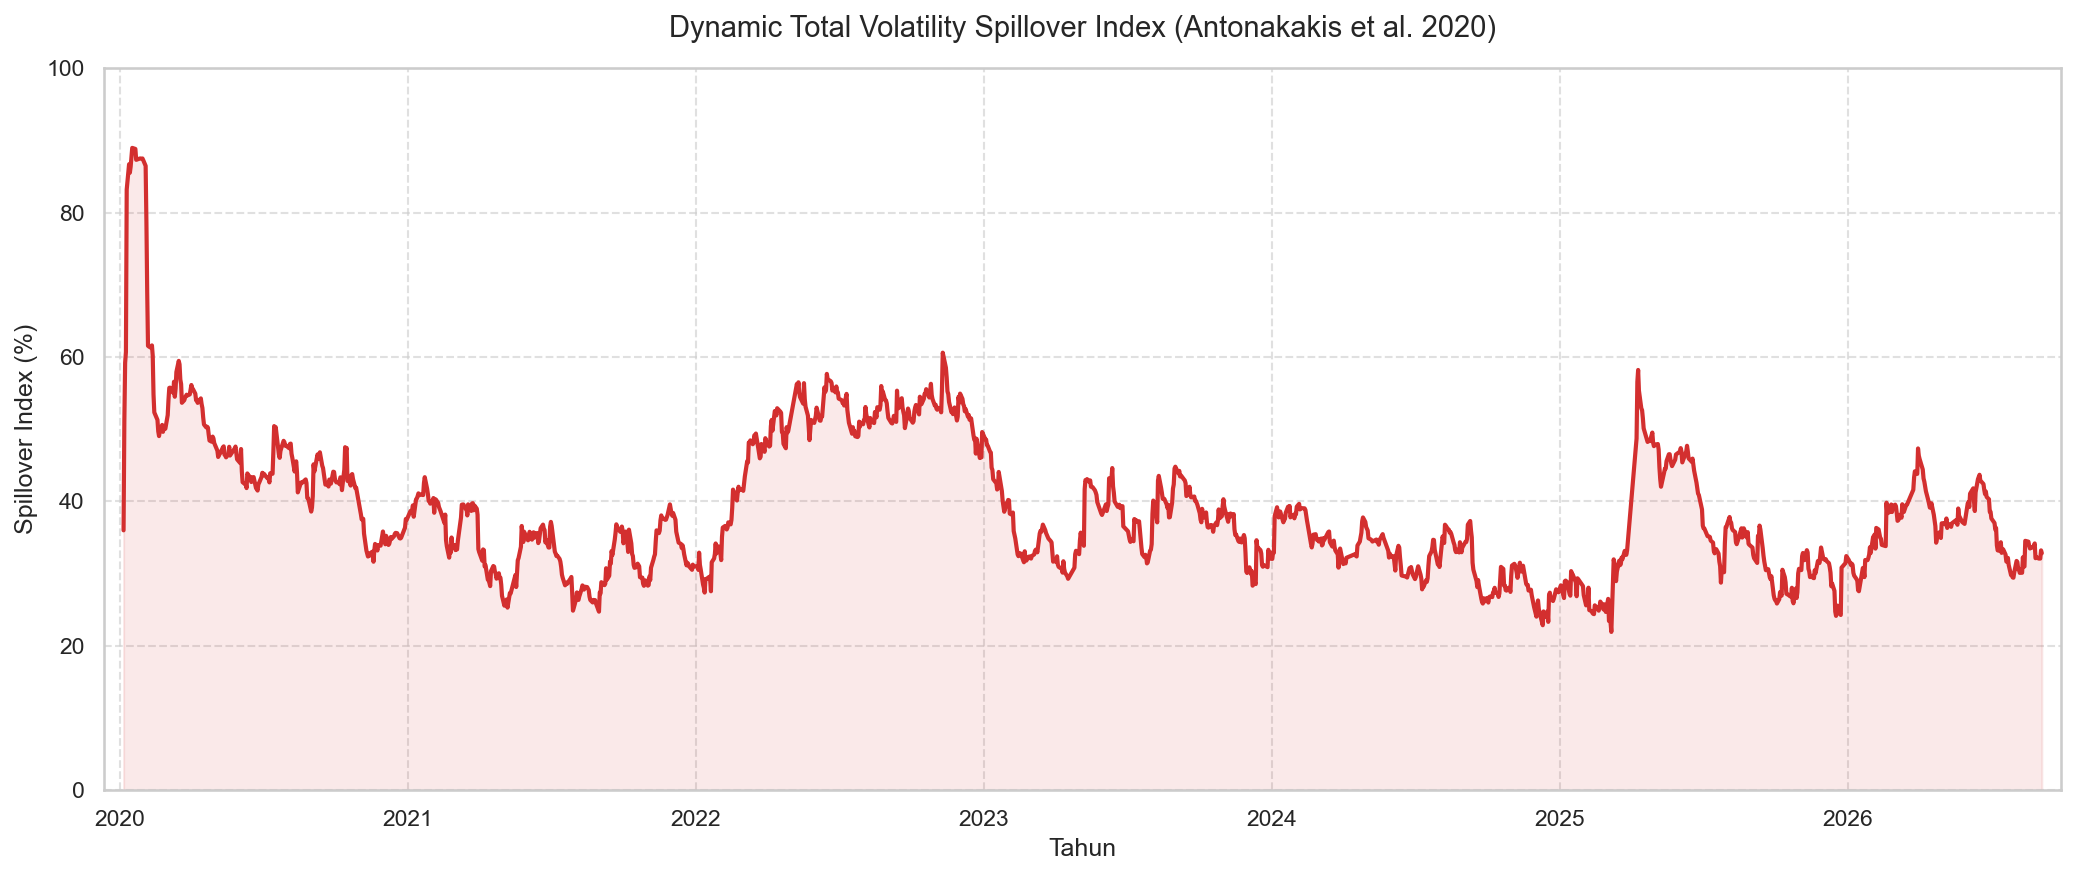

In [44]:
plt.figure(figsize=(14, 6))
plt.plot(plot_dates, tsi, color='#d32f2f', linewidth=2)
plt.fill_between(plot_dates, tsi, alpha=0.1, color='#d32f2f')
plt.title('Dynamic Total Volatility Spillover Index (Antonakakis et al. 2020)', fontsize=14, pad=15)
plt.ylabel('Spillover Index (%)', fontsize=12)
plt.xlabel('Tahun', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)
plt.margins(x=0.01)
plt.ylim(0, 100)
plt.tight_layout()

# Simpan visualisasi
os.makedirs(RESULTS_DIR, exist_ok=True)
plt.savefig(os.path.join(RESULTS_DIR, 'Total_Spillover_Index.png'), dpi=300)
plt.show()

### 5.2 Net Spillover
Mengidentifikasi apakah instrumen tertentu adalah **Net Transmitter** (> 0) atau **Net Receiver** (< 0).

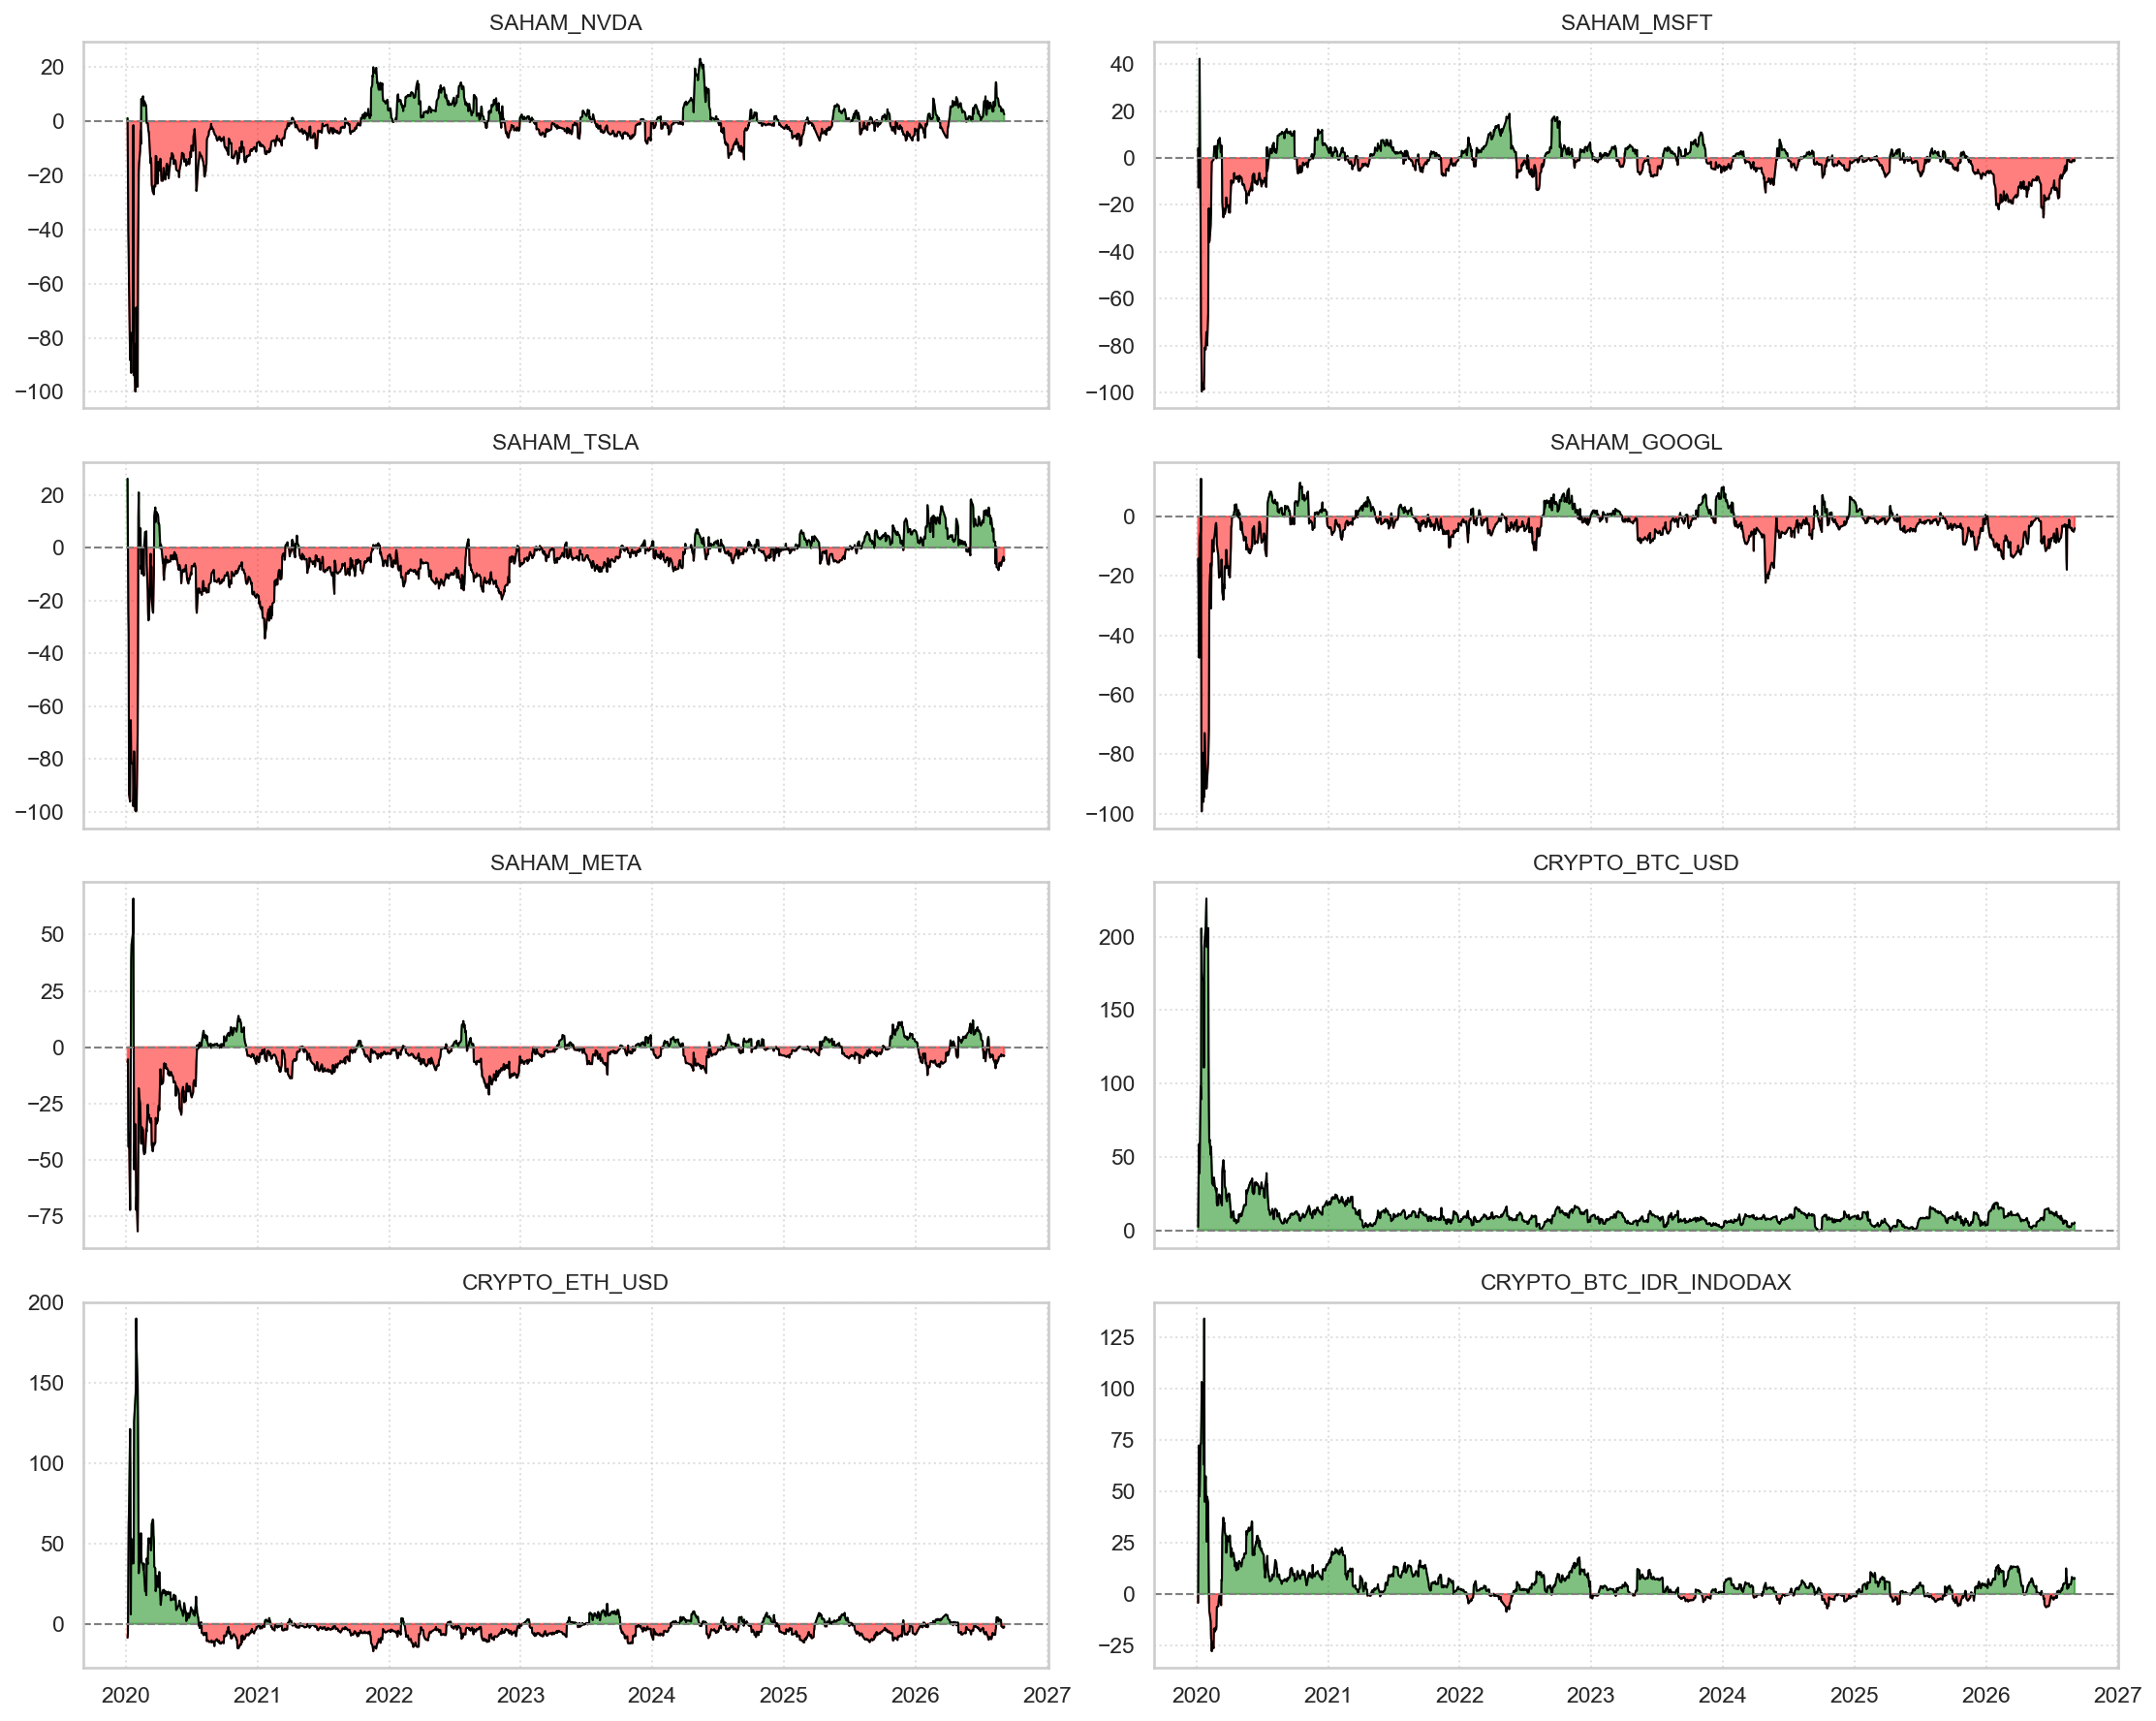

In [45]:
fig, axes = plt.subplots(4, 2, figsize=(15, 12), sharex=True)
axes = axes.flatten()

for i, ax in enumerate(axes):
    ax.plot(plot_dates, net_spill[:, i], color='black', linewidth=1)
    ax.fill_between(plot_dates, 0, net_spill[:, i], where=(net_spill[:, i] > 0), color='green', alpha=0.5, interpolate=True, label='Net Transmitter')
    ax.fill_between(plot_dates, 0, net_spill[:, i], where=(net_spill[:, i] < 0), color='red', alpha=0.5, interpolate=True, label='Net Receiver')
    ax.axhline(0, color='grey', linestyle='--', linewidth=1)
    ax.set_title(core_vars[i].replace('ret_', '').upper(), fontsize=11)
    ax.grid(True, linestyle=':', alpha=0.6)
    
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'Net_Spillovers.png'), dpi=300)
plt.show()

## 6. Average Spillover Table
Tabel rata-rata seluruh periode (Diebold-Yilmaz Connectedness Table). Baris mewakili 'FROM', Kolom mewakili 'TO'.

,SAHAM_NVDA,SAHAM_MSFT,SAHAM_TSLA,SAHAM_GOOGL,SAHAM_META,CRYPTO_BTC_USD,CRYPTO_ETH_USD,CRYPTO_BTC_IDR_INDODAX,FROM Others
SAHAM_NVDA,69.38,6.39,3.92,5.13,5.98,3.12,3.26,2.82,30.62
SAHAM_MSFT,6.29,62.00,4.01,9.38,7.95,4.04,3.04,3.29,38.00
SAHAM_TSLA,3.99,4.78,74.68,3.49,3.46,3.27,3.65,2.68,25.32
SAHAM_GOOGL,5.64,9.61,3.33,64.56,8.39,3.01,3.15,2.30,35.44
SAHAM_META,5.90,8.01,3.45,8.31,65.42,2.84,3.34,2.73,34.58
CRYPTO_BTC_USD,1.66,2.52,1.61,1.96,1.42,47.27,14.22,29.35,52.73
CRYPTO_ETH_USD,2.64,2.26,2.33,2.37,1.92,17.46,57.74,13.28,42.26
CRYPTO_BTC_IDR_INDODAX,2.18,2.09,1.92,1.38,1.44,30.78,11.21,49.01,50.99
TO Others,28.30,35.66,20.56,32.02,30.56,64.53,41.86,56.44,38.74
NET Spillover,-2.32,-2.34,-4.76,-3.42,-4.01,11.80,-0.40,5.45,NaN


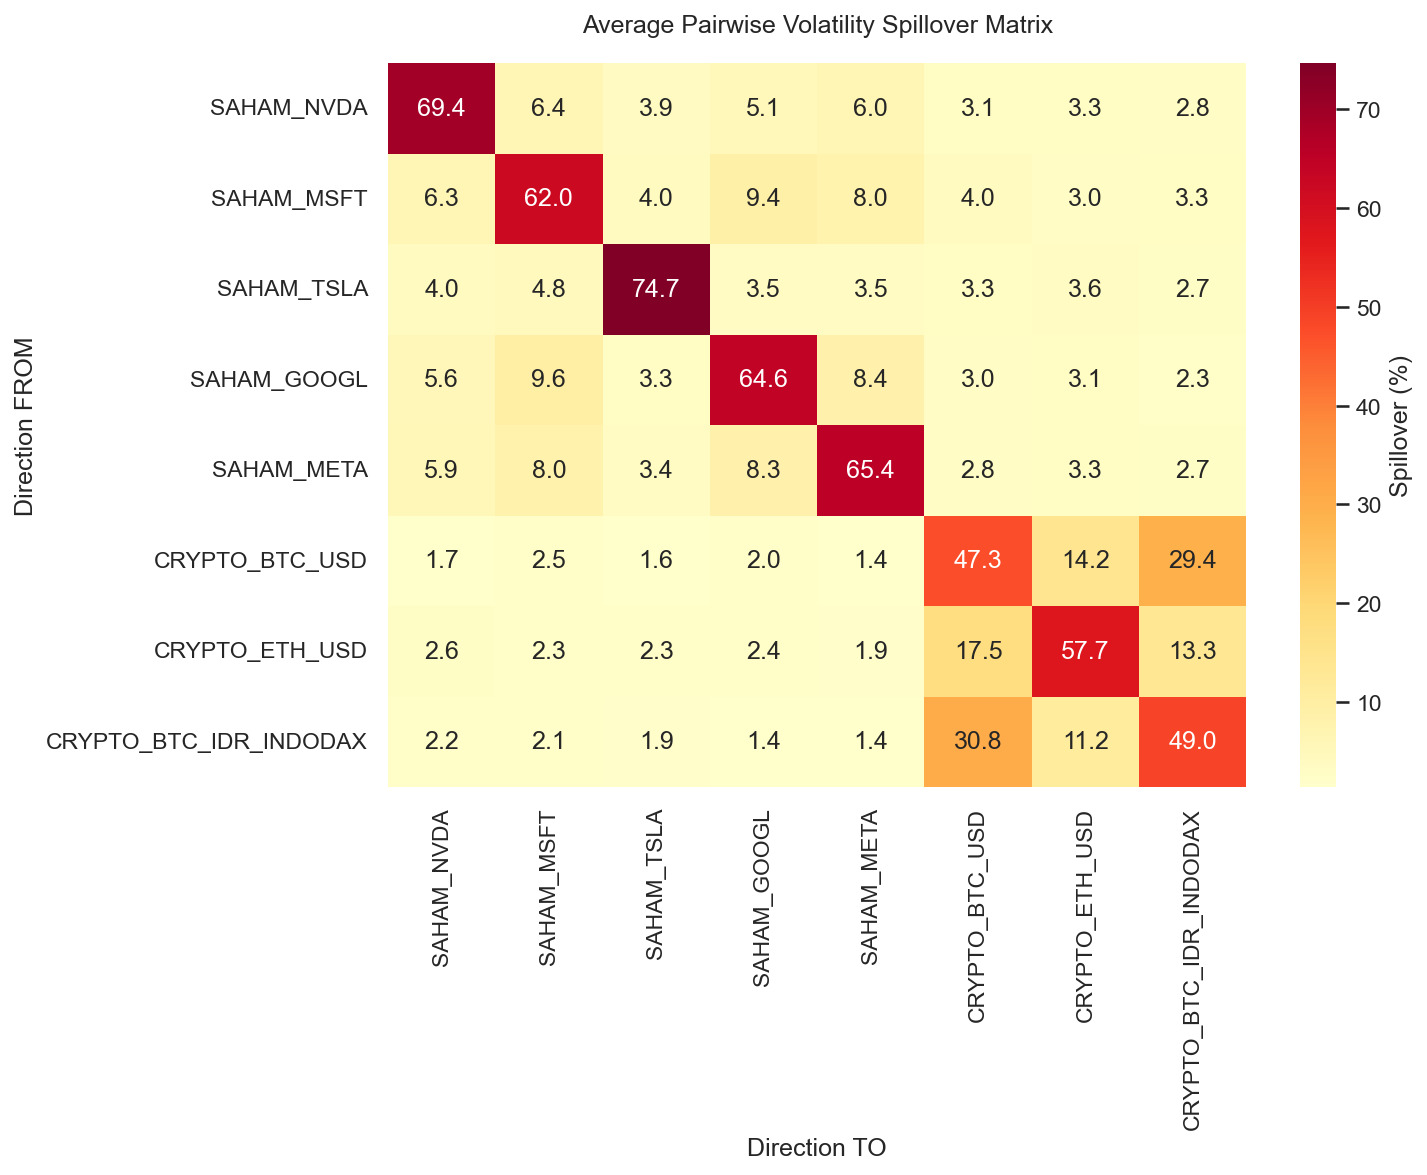

In [46]:
# Rata-rata dari seluruh history GFEVD
avg_gfevd = gfevd_hist.mean(axis=0) * 100

var_labels = [v.replace('ret_', '').upper() for v in core_vars]

table = pd.DataFrame(avg_gfevd, index=var_labels, columns=var_labels)
diag_vals = np.diag(table)

table['FROM Others'] = table.sum(axis=1) - diag_vals

# Hitung TO Others per aset (hanya kolom 0..M-1)
to_others = table.iloc[:M, :M].sum(axis=0) - diag_vals
table.loc['TO Others'] = list(to_others) + [np.mean(tsi)]

# Hitung NET Spillover (TO - FROM)
net_spillover = to_others - table['FROM Others'].iloc[:M]
table.loc['NET Spillover'] = list(net_spillover) + [np.nan]

# Format ke 2 angka desimal
formatted_table = table.round(2)
formatted_table.to_csv(os.path.join(RESULTS_DIR, 'Average_Spillover_Table.csv'))

display(formatted_table)

# Plot Heatmap rata-rata
plt.figure(figsize=(10, 8))
sns.heatmap(table.iloc[:M, :M], annot=True, fmt=".1f", cmap='YlOrRd', cbar_kws={'label': 'Spillover (%)'})
plt.title('Average Pairwise Volatility Spillover Matrix', pad=15)
plt.ylabel('Direction FROM')
plt.xlabel('Direction TO')
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, 'Pairwise_Spillover_Heatmap.png'), dpi=300)
plt.show()

In [47]:
# 3. SENSITIVITY CHECK 9-KOMBINASI & 4. CEK TANGGAL DATA
print("=== (4) RENTANG TANGGAL DATA ===")
print(f"Tanggal Minimum: {dates.min()}")
print(f"Tanggal Maksimum: {dates.max()}")

print("\n=== (3) UJI ROBUSTNESS 9-KOMBINASI (META & BTC-IDR Net Spillover) ===")
lambda_list = [0.98, 0.99, 0.995]
kappa_list = [0.94, 0.96, 0.98]
sens_results = []

idx_meta = core_vars.index("ret_saham_meta")
idx_btcidr = core_vars.index("ret_crypto_btc_idr_indodax")

for l_ff in lambda_list:
    for k_ff in kappa_list:
        print(f"Estimating lambda={l_ff}, kappa={k_ff} ...")
        # Estimate
        model_sens = ForgettingFactorTVPVAR(Y_std, p=p_lag, lambda_ff=l_ff, kappa_ff=k_ff)
        b_hist, s_hist = model_sens.estimate()
        # GFEVD
        gf_hist = calculate_gfevd(b_hist, s_hist, M=len(core_vars), p=p_lag, H=10)
        # Avg
        avg_gf = gf_hist.mean(axis=0) * 100
        diag_v = np.diag(avg_gf)
        from_oth = avg_gf.sum(axis=1) - diag_v
        to_oth = avg_gf.sum(axis=0) - diag_v
        net_spill_sens = to_oth - from_oth
        
        sens_results.append({
            "Lambda": l_ff,
            "Kappa": k_ff,
            "META Net Spillover": net_spill_sens[idx_meta],
            "BTC-IDR Net Spillover": net_spill_sens[idx_btcidr]
        })

df_sens = pd.DataFrame(sens_results)
print("\nTABEL HASIL SENSITIVITY CHECK:")
display(df_sens)


=== (4) RENTANG TANGGAL DATA ===
Tanggal Minimum: 2020-01-03 00:00:00
Tanggal Maksimum: 2026-09-04 00:00:00

=== (3) UJI ROBUSTNESS 9-KOMBINASI (META & BTC-IDR Net Spillover) ===
Estimating lambda=0.98, kappa=0.94 ...
Estimating lambda=0.98, kappa=0.96 ...
Estimating lambda=0.98, kappa=0.98 ...
Estimating lambda=0.99, kappa=0.94 ...
Estimating lambda=0.99, kappa=0.96 ...
Estimating lambda=0.99, kappa=0.98 ...
Estimating lambda=0.995, kappa=0.94 ...
Estimating lambda=0.995, kappa=0.96 ...
Estimating lambda=0.995, kappa=0.98 ...

TABEL HASIL SENSITIVITY CHECK:


,Lambda,Kappa,META Net Spillover,BTC-IDR Net Spillover
0,0.980,0.94,-4.374624,4.992500
1,0.980,0.96,-4.597054,4.622644
2,0.980,0.98,-4.902709,3.988437
3,0.990,0.94,-4.034658,5.726810
4,0.990,0.96,-4.013171,5.454596
5,0.990,0.98,-4.114565,4.945084
6,0.995,0.94,-4.295691,6.437236
7,0.995,0.96,-4.113522,6.093738
8,0.995,0.98,-4.026494,5.643986


In [48]:
# 4. RE-GENERATE & EXPORT TVP-VAR DYNAMIC FEATURES (TIME-SERIES)
print("=== EXPORT TVP-VAR DYNAMIC FEATURES ===")
import pandas as pd
import numpy as np
import os
import shutil

output_path = os.path.join(CLEAN_DATA_DIR, "tvp_var_dynamic_features.csv")
old_path_temp = os.path.join(CLEAN_DATA_DIR, "tvp_var_dynamic_features_old_backup.csv")

# Backup old file if exists
if os.path.exists(output_path):
    shutil.copy2(output_path, old_path_temp)

df_dynamic = pd.DataFrame({"Date": plot_dates})

# 1. TVP-TSI (Total Spillover Index time-varying)
df_dynamic["tvp_tsi"] = tsi

# 2. Net Spillover per aset
for i, var in enumerate(core_vars):
    col_name = var.replace("ret_", "net_spill_")
    df_dynamic[col_name] = net_spill[:, i]

# 3. Spillover AI to BTC-IDR (Time-varying)
idx_btcidr = 7
spill_ai_to_btc = np.sum(gfevd_hist[:, idx_btcidr, 0:5], axis=1) * 100
df_dynamic["spillover_ai_to_btcidr"] = spill_ai_to_btc

cols_order = [
    "Date", "tvp_tsi", 
    "net_spill_saham_nvda", "net_spill_saham_msft", "net_spill_saham_tsla", 
    "net_spill_saham_googl", "net_spill_saham_meta", "net_spill_crypto_btc_usd", 
    "net_spill_crypto_eth_usd", "net_spill_crypto_btc_idr_indodax", 
    "spillover_ai_to_btcidr"
]
df_dynamic = df_dynamic[cols_order]

os.makedirs(CLEAN_DATA_DIR, exist_ok=True)
df_dynamic.to_csv(output_path, index=False)
print(f"Berhasil menyimpan dynamic features ke {output_path} (Shape: {df_dynamic.shape})")

if os.path.exists(old_path_temp):
    df_old = pd.read_csv(old_path_temp, parse_dates=["Date"])
    df_new = pd.read_csv(output_path, parse_dates=["Date"])
    
    print(f"\n[PERBANDINGAN] Baris File Lama: {len(df_old)}, Baris File Baru: {len(df_new)}")
    
    diffs = []
    if len(df_old) == len(df_new):
        for col in cols_order:
            if col != "Date":
                mae = (df_new[col] - df_old[col]).abs().mean()
                diffs.append((col, mae))
        
        print("Mean Absolute Error (MAE) Baru vs Lama:")
        for c, m in diffs:
            print(f"  - {c}: {m:.6e}")
        
        if sum([m for _, m in diffs]) < 1e-5:
            print("\nKESIMPULAN: Identik (Perbedaan hanya di level floating-point limit/Sangat kecil) ✅")
        else:
            print("\nKESIMPULAN: BERBEDA! File baru dan lama menghasilkan nilai yang berbeda. ❌")
    else:
         print("\nKESIMPULAN: BERBEDA BARIS! File baru dan lama memiliki jumlah baris berbeda. ❌")


=== EXPORT TVP-VAR DYNAMIC FEATURES ===
Berhasil menyimpan dynamic features ke data_clean/tvp_var_dynamic_features.csv (Shape: (1555, 11))

[PERBANDINGAN] Baris File Lama: 1555, Baris File Baru: 1555
Mean Absolute Error (MAE) Baru vs Lama:
  - tvp_tsi: 2.452946e+01
  - net_spill_saham_nvda: 1.761490e+01
  - net_spill_saham_msft: 9.895325e+00
  - net_spill_saham_tsla: 1.671396e+01
  - net_spill_saham_googl: 9.506785e+00
  - net_spill_saham_meta: 1.168017e+01
  - net_spill_crypto_btc_usd: 1.319445e+01
  - net_spill_crypto_eth_usd: 1.215004e+01
  - net_spill_crypto_btc_idr_indodax: 1.233200e+01
  - spillover_ai_to_btcidr: 1.540598e+01

KESIMPULAN: BERBEDA! File baru dan lama menghasilkan nilai yang berbeda. ❌
